# Regresión de precios de casas — entrenamiento LOCAL + deploy en SageMaker

Este notebook es una copia de `linear-learner-houses.ipynb` con **un solo cambio de fondo**:
el entrenamiento ocurre **en esta computadora** en vez de en una instancia de entrenamiento de AWS.

## ¿Por qué?

Las cuotas de esta cuenta en **us-east-2** (la región donde está el bucket) están así:

| Cuota | Valor | Consecuencia |
|---|---|---|
| `ml.m4.xlarge` **for training job usage** | **0** | ❌ no se puede entrenar |
| `ml.m5.xlarge` **for training job usage** | **0** | ❌ no se puede entrenar |
| *cualquier* instancia **for training job usage** | **0** | ❌ `linear.fit()` falla siempre |
| `ml.m5.xlarge` **for endpoint usage** | **0** | ❌ el deploy original también fallaba |
| `ml.m4.xlarge` **for endpoint usage** | **6** | ✅ **sí podemos publicar el endpoint** |
| `ml.t3.medium` for processing job usage | 4 | ✅ (lo usa el otro notebook) |

Se comprueba con:

```bash
aws service-quotas list-service-quotas --service-code sagemaker --region us-east-2   --query "Quotas[?contains(QuotaName,'ml.m4.xlarge')].[QuotaName,Value]" --output table
```

Entonces: **entrenamos gratis en la laptop y publicamos el endpoint en `ml.m4.xlarge`**, que es la
cuota que sí tenemos.

## ¿Qué se conserva y qué cambia?

| Etapa | Notebook original | Este notebook |
|---|---|---|
| Carga y análisis de datos | pandas / seaborn | 🟢 **idéntico** |
| Preprocesamiento (`X`, `y`, split 70/30) | idem | 🟢 **idéntico** |
| Conversión a RecordIO-Protobuf | `smac.write_numpy_to_dense_tensor` | 🟢 **idéntico** |
| Subida del dataset a S3 | `boto3` | 🟢 **idéntico** |
| **Entrenamiento** | `Estimator(linear-learner).fit()` en `ml.m4.xlarge` | 🟡 **el mismo algoritmo, reimplementado en NumPy, corriendo aquí** |
| Empaquetado del modelo | lo hace AWS (`model.tar.gz` → S3) | 🟡 **lo hacemos nosotros (`model.tar.gz` → S3)** |
| Deploy del endpoint | `.deploy(ml.m5.xlarge)` | 🟡 **`.deploy(ml.m4.xlarge)`** |
| Contrato del endpoint | `text/csv` → `{"predictions":[{"score":…}]}` | 🟢 **idéntico** (los scripts de consumo no cambian) |

> **Nota importante:** no se necesita Docker en esta máquina. El contenedor del endpoint lo descarga
> AWS del lado de la instancia `ml.m4.xlarge`; nosotros solo subimos el modelo a S3.

### Entorno

```bash
conda create -y -n MLOps-AWS-Regresion-Houses python=3.11
conda activate MLOps-AWS-Regresion-Houses
pip install "sagemaker<3" boto3 pandas numpy scikit-learn matplotlib seaborn python-dotenv ipykernel
```

Ojo con la versión del SDK: **`sagemaker` 3.x es una reescritura** en la que ya no existen
`sagemaker.session`, `sagemaker.amazon.common` (RecordIO) ni `Estimator`. Este notebook usa el
SDK **v2**, que es el que expone la API clásica que ya conocemos.

In [1]:
# === Compatibilidad del SDK de SageMaker (funciona en v2 y en v3) ===
import os
os.environ['SAGEMAKER_SUPPRESS_V2_WARNING'] = '1'

import sagemaker
from importlib.metadata import version

try:
    # SDK v2 (y v3 temprano): la API clásica vive en sagemaker.session
    from sagemaker.session import Session, get_execution_role
    sagemaker.Session = Session
    sagemaker.get_execution_role = get_execution_role
    print("API clásica disponible")
except ImportError:
    print("Este SDK ya no expone la API clásica; instala 'sagemaker<3'")

print("SDK SageMaker:", version("sagemaker"))

sagemaker.config INFO - Not applying SDK defaults from location: /Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Users/kevininofuente/Library/Application Support/sagemaker/config.yaml
API clásica disponible
SDK SageMaker: 2.257.6


# Carregamento da base de dados

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np

In [3]:
base_casas = pd.read_csv('house_prices.csv')
base_casas

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [4]:
base_casas.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')

In [5]:
base_casas.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


### Búsqueda de Missing Values

In [6]:
base_casas.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

# Visualização dos dados

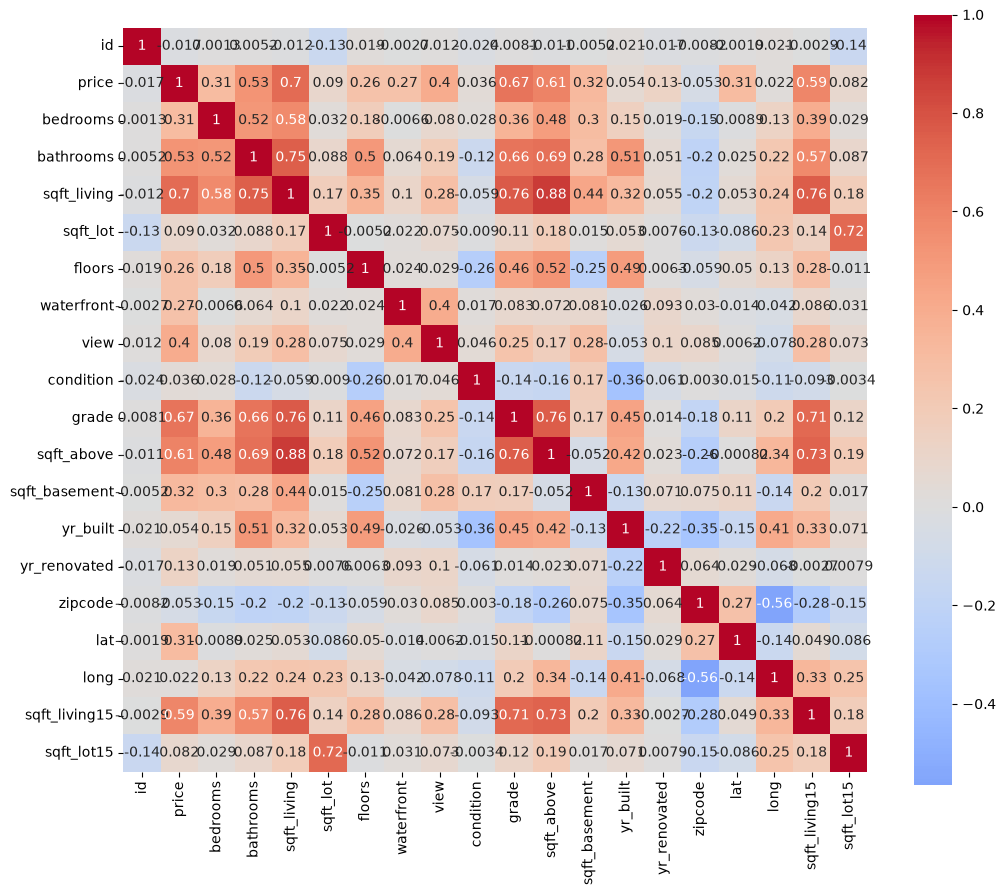

In [7]:
numeric_cols = base_casas.select_dtypes(include=['int64', 'float64']).columns
correlacion = base_casas[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlacion, cmap='coolwarm', center=0, square=True, annot=True)
plt.show()

# Pré-processamento dos dados

In [8]:
base_casas.columns

Index(['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
       'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
       'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode',
       'lat', 'long', 'sqft_living15', 'sqft_lot15'],
      dtype='str')

In [9]:
#Solo cogemos las columnas desde "bedrooms" hasta la columna "long"
X = base_casas.iloc[:, 3:19].values
X

array([[ 3.00000e+00,  1.00000e+00,  1.18000e+03, ...,  9.81780e+04,
         4.75112e+01, -1.22257e+02],
       [ 3.00000e+00,  2.25000e+00,  2.57000e+03, ...,  9.81250e+04,
         4.77210e+01, -1.22319e+02],
       [ 2.00000e+00,  1.00000e+00,  7.70000e+02, ...,  9.80280e+04,
         4.77379e+01, -1.22233e+02],
       ...,
       [ 2.00000e+00,  7.50000e-01,  1.02000e+03, ...,  9.81440e+04,
         4.75944e+01, -1.22299e+02],
       [ 3.00000e+00,  2.50000e+00,  1.60000e+03, ...,  9.80270e+04,
         4.75345e+01, -1.22069e+02],
       [ 2.00000e+00,  7.50000e-01,  1.02000e+03, ...,  9.81440e+04,
         4.75941e+01, -1.22299e+02]], shape=(21613, 16))

In [10]:
X.shape

(21613, 16)

In [11]:
#Vemos los datos de la primera casa (fila)
X[0]

array([ 3.00000e+00,  1.00000e+00,  1.18000e+03,  5.65000e+03,
        1.00000e+00,  0.00000e+00,  0.00000e+00,  3.00000e+00,
        7.00000e+00,  1.18000e+03,  0.00000e+00,  1.95500e+03,
        0.00000e+00,  9.81780e+04,  4.75112e+01, -1.22257e+02])

### Observamos los precios de las casas

In [12]:
y = base_casas.iloc[:, 2].values
y

array([221900., 538000., 180000., ..., 402101., 400000., 325000.],
      shape=(21613,))

In [13]:
y.shape

(21613,)

### Necesitamos convertir X y Y a Vector

In [14]:
X = np.array(X).astype('float32')
y = np.array(y).astype('float32')

### Dividimos el dataset en entrenamiento y prueba

In [15]:
from sklearn.model_selection import train_test_split

X_entrenamiento, X_test, y_entrenamiento, y_test = train_test_split(X, y, test_size = 0.3, random_state=0)

In [16]:
X_entrenamiento.shape, X_test.shape

((15129, 16), (6484, 16))

In [17]:
y_entrenamiento.shape, y_test.shape

((15129,), (6484,))

In [18]:
X_entrenamiento.min(), X_entrenamiento.max()

(np.float32(-122.514), np.float32(1.651359e+06))

# Configuraciones SageMaker

### Importación de librerías

### La región: el error más silencioso de todos

`boto3` toma la región de `~/.aws/config` si no le dices otra cosa. Si esa región no es la misma
donde está el bucket, SageMaker falla con un mensaje que apunta al lugar equivocado:

```
ValidationException: Could not access model data at s3://.../model.tar.gz.
Please ensure that the role ... exists and that its trust relationship policy allows
"sts:AssumeRole" ... Also ensure that the role has "s3:GetObject" permissions
and that the object is located in us-east-1.
```

El mensaje culpa al rol IAM, pero el rol está perfecto: **el problema es que el bucket está en
us-east-2 y SageMaker estaba corriendo en us-east-1**. El artefacto del modelo tiene que estar
en la MISMA región que el endpoint.

Así que fijamos la región a mano y no dependemos del default del CLI:

In [19]:
import boto3

REGION = 'us-east-2'          # donde está el bucket Y donde tenemos la cuota de ml.m4.xlarge

# setup_default_session hace que TODO boto3 de aquí en adelante use esta región,
# incluida la Session() de SageMaker que creamos en la siguiente celda
boto3.setup_default_session(region_name=REGION)

# Ojo: boto3.Session() construye una sesión NUEVA que vuelve a leer ~/.aws/config.
# La que acabamos de fijar es boto3.DEFAULT_SESSION, y es la que usan
# boto3.client(...), boto3.resource(...) y la Session() de SageMaker.
print('Región de la sesión por defecto:', boto3.DEFAULT_SESSION.region_name)
print('Región de una sesión nueva     :', boto3.Session().region_name, ' <- la del ~/.aws/config')
print('Identidad:', boto3.client('sts').get_caller_identity()['Arn'])

Región de la sesión por defecto: us-east-2
Región de una sesión nueva     : us-east-1  <- la del ~/.aws/config
Identidad: arn:aws:iam::123456789012:user/tu-usuario-iam


In [20]:
import sagemaker
import boto3
from sagemaker.session import Session

sess = Session()

### Configuración del Bucket y rutas

In [21]:
session = Session()   # ya la importaste arriba
bucket = 'aws-sagemaker-datapath-ml-regresion-linear-learner-k'
subcarpeta_modelo = 'modelos/house-prices/linear-learner'
subcarpeta_dataset = 'datasets/house-prices'

### Rol de ejecución (IAM Role)

En SageMaker Studio bastaba `sagemaker.get_execution_role()`: ahí el notebook **ya corre con un rol**
y la función simplemente lo lee.

Desde tu laptop no existe ese "rol de sesión" — te autenticas como **usuario IAM**, no como rol. Así que
`get_execution_role()` falla. Hay que decirle explícitamente a SageMaker **con qué rol debe correr el
endpoint** (ese rol es el que le da permiso para leer el modelo de S3 y escribir logs en CloudWatch).

In [22]:
# Buscamos automáticamente el rol de ejecución de SageMaker que ya existe en la cuenta
iam = boto3.client('iam')

roles = [r['Arn'] for pagina in iam.get_paginator('list_roles').paginate()
         for r in pagina['Roles']
         if r['RoleName'].startswith('AmazonSageMaker-ExecutionRole')]

if roles:
    role = roles[0]
else:
    # Si no hay ninguno: consola de IAM -> Crear rol -> Caso de uso "SageMaker"
    raise RuntimeError("No se encontró un rol AmazonSageMaker-ExecutionRole en esta cuenta")

print("Rol de ejecución:", role)
print("Identidad con la que estamos autenticados:",
      boto3.client('sts').get_caller_identity()['Arn'])

Rol de ejecución: arn:aws:iam::123456789012:role/service-role/AmazonSageMaker-ExecutionRole-20260818T191520
Identidad con la que estamos autenticados: arn:aws:iam::123456789012:user/tu-usuario-iam


### Conversión de datos a formato RecordIO-Protobuf
#### SageMaker Linear Learner requiere que los datos estén en un formato binario específico llamado **RecordIO-Protobuf** (es mucho más eficiente que CSV para entrenar modelos grandes).

> Para entrenar en la laptop no necesitamos RecordIO — NumPy trabaja directo con los arrays.
> Igual mantenemos este paso porque:
> 1. Es el formato que **exigiría** un training job de SageMaker, y es parte de lo que hay que entender.
> 2. Deja el dataset versionado en S3, que es la práctica correcta: **los datos viven en S3**, no en la laptop.
> 3. El notebook de la variante que entrena en AWS (`linear-learner-houses-PROCESSING-JOB.ipynb`) lo consume.

In [23]:
import io
import sagemaker.amazon.common as smac # sagemaker commom library

buffer = io.BytesIO()
smac.write_numpy_to_dense_tensor(buffer, X_entrenamiento, y_entrenamiento)
buffer.seek(0)

0

### Subida de datos a S3
#### **key** → Nombre del archivo: `houses-train-data`
#### Se sube a la ruta: `datasets/house-prices/train/houses-train-data`.

In [24]:
import os
key = 'houses-train-data' #Base de datos de Entrenamiento
boto3.resource('s3').Bucket(bucket).Object(os.path.join(subcarpeta_dataset, 'train', key)).upload_fileobj(buffer)

In [25]:
os.path.join(subcarpeta_dataset, 'train', key)

'datasets/house-prices/train/houses-train-data'

### Definición de rutas finales
**s3_train_data** → Ruta completa de los datos de entrenamiento en S3.

**output_location** → Ruta donde SageMaker guardará el modelo entrenado cuando termine el proceso.

In [26]:
#Verificamos que esté en S3
s3_train_data = 's3://{}/{}/train/{}'.format(bucket, subcarpeta_dataset, key)
print('Localizacion de la base de entrenamiento: {}'.format(s3_train_data))

Localizacion de la base de entrenamiento: s3://aws-sagemaker-datapath-ml-regresion-linear-learner-k/datasets/house-prices/train/houses-train-data


In [27]:
output_location = 's3://{}/{}/output'.format(bucket, subcarpeta_modelo)
print('Modelo final será guardado en: {}'.format(output_location))

Modelo final será guardado en: s3://aws-sagemaker-datapath-ml-regresion-linear-learner-k/modelos/house-prices/linear-learner/output


# Creación y entrenamiento del Linear Learner — aquí, en la laptop

Esta es la única parte que cambia de fondo. En el notebook original era:

```python
linear = Estimator(image_uri=container, role=role, instance_count=1,
                   instance_type='ml.m4.xlarge', ...)          # <- necesita cuota de training
linear.set_hyperparameters(feature_dim=16, predictor_type='regressor', num_models=16)
linear.fit({'train': s3_train_data})                            # <- aquí explotaba
```

### ¿Qué hace realmente `linear-learner` por dentro?

No es magia: es un **modelo lineal entrenado con descenso de gradiente**. La
[documentación de AWS](https://docs.aws.amazon.com/sagemaker/latest/dg/ll_hyperparameters.html)
dice exactamente qué usa por defecto, y eso es lo que reimplementamos:

| Hiperparámetro de AWS | Valor | Qué implementamos |
|---|---|---|
| `predictor_type='regressor'` | (lo pusimos nosotros) | pérdida cuadrática (MSE) |
| `num_models=16` | (lo pusimos nosotros) | **16 modelos en paralelo**, gana el de menor error de validación |
| `feature_dim=16` | (lo pusimos nosotros) | 16 columnas de entrada |
| `optimizer` | `adam` | Adam con β₁=0.9, β₂=0.999 |
| `loss` | `squared_loss` | idem |
| `mini_batch_size` | `1000` | mini-batches de 1000 filas |
| `normalize_data` | `true` | normalizamos las features con media/desvío del **train** |
| `normalize_label` | `true` | normalizamos también el precio (es regresión) |

Lo más interesante de `num_models` es que **no es un ensamble**: AWS entrena N modelos con distintas
combinaciones de *learning rate* y regularización y se queda **solo con el mejor**. Es una búsqueda
de hiperparámetros disfrazada. Eso es lo que hace la celda de abajo.

In [28]:
# ============================================================================
# Reimplementación de linear-learner: modelo lineal + Adam sobre mini-batches
# (el mismo código vive en code/linear_learner_local.py, para reutilizarlo)
# ============================================================================
import numpy as np

MINI_BATCH_SIZE = 1000     # mini_batch_size por defecto de linear-learner
EPOCAS = 200               # AWS usa 15; subimos porque en CPU local nos sobra tiempo
BETA1, BETA2, EPS = 0.9, 0.999, 1e-8


def _adam(X, y, learning_rate, wd, epocas, mini_batch_size, semilla):
    '''Entrena UN modelo lineal con Adam. X e y ya vienen normalizados.'''
    rng = np.random.default_rng(semilla)
    n, d = X.shape

    w, b = np.zeros(d), 0.0                    # pesos y sesgo
    mw, vw, mb, vb = np.zeros(d), np.zeros(d), 0.0, 0.0
    t = 0

    for _ in range(epocas):
        orden = rng.permutation(n)                              # se mezcla cada época
        for inicio in range(0, n, mini_batch_size):
            idx = orden[inicio:inicio + mini_batch_size]
            Xb, yb = X[idx], y[idx]
            m = len(idx)

            # gradiente de la pérdida cuadrática + regularización L2 (weight decay)
            error = Xb @ w + b - yb
            gw = (2.0 / m) * (Xb.T @ error) + 2.0 * wd * w
            gb = (2.0 / m) * error.sum()

            # --- Adam: promedio móvil del gradiente y de su cuadrado
            t += 1
            mw = BETA1 * mw + (1 - BETA1) * gw
            vw = BETA2 * vw + (1 - BETA2) * gw ** 2
            mb = BETA1 * mb + (1 - BETA1) * gb
            vb = BETA2 * vb + (1 - BETA2) * gb ** 2

            mw_c, vw_c = mw / (1 - BETA1 ** t), vw / (1 - BETA2 ** t)   # corrección de sesgo
            mb_c, vb_c = mb / (1 - BETA1 ** t), vb / (1 - BETA2 ** t)

            w -= learning_rate * mw_c / (np.sqrt(vw_c) + EPS)
            b -= learning_rate * mb_c / (np.sqrt(vb_c) + EPS)

    return w, b

In [29]:
def entrenar_linear_learner(X_entrenamiento, y_entrenamiento, num_models=16,
                            epocas=EPOCAS, mini_batch_size=MINI_BATCH_SIZE,
                            fraccion_validacion=0.2, semilla=0):
    '''
    Entrena num_models modelos y devuelve el mejor, igual que linear-learner.

    Devuelve un diccionario de números (no un objeto de sklearn) para que el
    artefacto sea portable entre versiones de librerías.
    '''
    X = np.asarray(X_entrenamiento, dtype=np.float64)
    y = np.asarray(y_entrenamiento, dtype=np.float64).ravel()

    # --- partición interna de validación, para poder elegir al ganador
    rng = np.random.default_rng(semilla)
    orden = rng.permutation(len(X))
    corte = int(len(X) * (1 - fraccion_validacion))
    tr, va = orden[:corte], orden[corte:]
    X_tr, y_tr, X_va, y_va = X[tr], y[tr], X[va], y[va]

    # --- normalize_data=True / normalize_label=True
    #     ¡las estadísticas se calculan SOLO con entrenamiento, nunca con validación!
    x_mean, x_std = X_tr.mean(axis=0), X_tr.std(axis=0)
    x_std[x_std == 0] = 1.0
    y_mean, y_std = y_tr.mean(), y_tr.std()

    X_tr_n, X_va_n = (X_tr - x_mean) / x_std, (X_va - x_mean) / x_std
    y_tr_n, y_va_n = (y_tr - y_mean) / y_std, (y_va - y_mean) / y_std

    # --- num_models: la rejilla de combinaciones que van a competir
    tasas  = [0.001, 0.005, 0.01, 0.05]
    decays = [0.0, 1e-6, 1e-4, 1e-2]
    combos = [(lr, wd) for lr in tasas for wd in decays][:num_models]

    resultados = []
    for i, (lr, wd) in enumerate(combos, start=1):
        w, b = _adam(X_tr_n, y_tr_n, lr, wd, epocas, mini_batch_size, semilla + i)
        mse_val = float(np.mean((X_va_n @ w + b - y_va_n) ** 2))
        resultados.append({'lr': lr, 'wd': wd, 'mse_val': mse_val, 'w': w, 'b': b})
        print(f'  modelo {i:2d}/{num_models}  learning_rate={lr:<6g} wd={wd:<8g}'
              f'  -> MSE validación = {mse_val:.6f}')

    mejor = min(resultados, key=lambda r: r['mse_val'])
    print(f"\n  >>> Gana learning_rate={mejor['lr']}, wd={mejor['wd']} (MSE={mejor['mse_val']:.6f})")

    return {
        'coef': mejor['w'],
        'intercept': float(mejor['b']),
        'x_mean': x_mean, 'x_std': x_std,
        'y_mean': float(y_mean), 'y_std': float(y_std),
        'hiperparametros': {'learning_rate': mejor['lr'], 'wd': mejor['wd'],
                            'epocas': epocas, 'mini_batch_size': mini_batch_size,
                            'num_models': num_models, 'predictor_type': 'regressor',
                            'feature_dim': X.shape[1]},
    }


def predecir(modelo, X):
    '''La MISMA matemática que corre dentro del endpoint (ver code/inference.py).'''
    X = np.asarray(X, dtype=np.float64)
    if X.ndim == 1:
        X = X.reshape(1, -1)
    X_n = (X - modelo['x_mean']) / modelo['x_std']
    return (X_n @ modelo['coef'] + modelo['intercept']) * modelo['y_std'] + modelo['y_mean']

In [30]:
# Aquí es donde antes decía linear.fit({'train': s3_train_data}) y fallaba por cuota.
import time

inicio = time.time()
modelo = entrenar_linear_learner(X_entrenamiento, y_entrenamiento,
                                 num_models=16)      # <- mismo num_models del original
print(f'\nEntrenamiento terminado en {time.time() - inicio:.1f} segundos, en esta laptop, gratis.')

  modelo  1/16  learning_rate=0.001  wd=0         -> MSE validación = 0.362387
  modelo  2/16  learning_rate=0.001  wd=1e-06     -> MSE validación = 0.361709
  modelo  3/16  learning_rate=0.001  wd=0.0001    -> MSE validación = 0.363174
  modelo  4/16  learning_rate=0.001  wd=0.01      -> MSE validación = 0.362321
  modelo  5/16  learning_rate=0.005  wd=0         -> MSE validación = 0.363612
  modelo  6/16  learning_rate=0.005  wd=1e-06     -> MSE validación = 0.364328
  modelo  7/16  learning_rate=0.005  wd=0.0001    -> MSE validación = 0.363910
  modelo  8/16  learning_rate=0.005  wd=0.01      -> MSE validación = 0.359240
  modelo  9/16  learning_rate=0.01   wd=0         -> MSE validación = 0.361730
  modelo 10/16  learning_rate=0.01   wd=1e-06     -> MSE validación = 0.359815
  modelo 11/16  learning_rate=0.01   wd=0.0001    -> MSE validación = 0.363750
  modelo 12/16  learning_rate=0.01   wd=0.01      -> MSE validación = 0.365566
  modelo 13/16  learning_rate=0.05   wd=0         ->

### Evaluación

Comparamos contra la **solución exacta** del problema (OLS por forma cerrada, `LinearRegression` de
scikit-learn). Ese es el techo teórico de cualquier modelo lineal sobre estos datos: si nuestro
descenso de gradiente llega ahí, entrenó bien.

In [32]:
from sklearn.linear_model import LinearRegression


def metricas(y_real, y_pred):
    y_real, y_pred = np.ravel(y_real), np.ravel(y_pred)
    residuo = y_real - y_pred
    ss_res = float(np.sum(residuo ** 2))
    ss_tot = float(np.sum((y_real - y_real.mean()) ** 2))
    return {'RMSE': float(np.sqrt(np.mean(residuo ** 2))),
            'MAE':  float(np.mean(np.abs(residuo))),
            'R2':   1.0 - ss_res / ss_tot}


y_pred_local = predecir(modelo, X_test)
m_local = metricas(y_test, y_pred_local)

ols = LinearRegression().fit(X_entrenamiento, y_entrenamiento)
m_ols = metricas(y_test, ols.predict(X_test))

print('Nuestro Linear Learner (Adam, 16 modelos):')
for k, v in m_local.items():
    print(f'   {k:<5} {v:>14,.4f}')
print('\nÓptimo teórico (OLS forma cerrada):')
for k, v in m_ols.items():
    print(f'   {k:<5} {v:>14,.4f}')
print(f"\nBrecha de R2 contra el óptimo: {abs(m_local['R2'] - m_ols['R2']):.6f}")

Nuestro Linear Learner (Adam, 16 modelos):
   RMSE    207,103.8070
   MAE     125,225.6751
   R2            0.6876

Óptimo teórico (OLS forma cerrada):
   RMSE    206,803.8906
   MAE     124,011.6875
   R2            0.6885

Brecha de R2 contra el óptimo: 0.000904


### Interpretación: ¿cuánto pesa cada variable, en dólares?

Los pesos que entrenamos están en el espacio normalizado. Si los devolvemos al espacio original
obtenemos algo que se lee directo: **cuántos dólares suma cada unidad de cada variable**.

In [33]:
# Devolvemos los coeficientes al espacio original (dólares por unidad)
coef_crudo = modelo['coef'] * modelo['y_std'] / modelo['x_std']
intercepto_crudo = (modelo['y_mean'] + modelo['y_std'] * modelo['intercept']
                    - float(np.sum(coef_crudo * modelo['x_mean'])))

nombres = list(base_casas.columns[3:19])
tabla = (pd.DataFrame({'variable': nombres, 'dolares_por_unidad': coef_crudo})
         .sort_values('dolares_por_unidad', key=abs, ascending=False)
         .reset_index(drop=True))

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
display(tabla)
print(f'intercepto: {intercepto_crudo:,.2f}')

,variable,dolares_por_unidad
0,lat,"620,365.05"
1,waterfront,"604,947.49"
2,long,"-212,829.29"
3,grade,"100,739.58"
4,view,"58,027.13"
5,bathrooms,"36,779.24"
6,condition,"29,440.68"
7,bedrooms,"-28,595.54"
8,floors,"4,790.29"
9,yr_built,"-2,545.43"


intercepto: -3,917,102.75


# Empaquetado del modelo en el formato que espera SageMaker

Cuando entrena AWS, al terminar el training job deja en `output_location` un archivo
**`model.tar.gz`**. Eso es todo lo que un endpoint necesita. Como entrenamos nosotros,
ahora **nosotros** armamos ese `model.tar.gz` y lo subimos al mismo lugar de S3.

### ¿Por qué guardamos el modelo como JSON y no como `.joblib`?

Porque el artefacto tiene que abrirse **dentro del contenedor de AWS**, que trae `numpy 1.x` y
`scikit-learn 1.2`. Esta laptop entrena con `numpy 2.x` y `scikit-learn 1.9`, y un *pickle*
(que es lo que hay dentro de un `.joblib`) creado con numpy 2 **no se puede leer con numpy 1**
— falla con `No module named numpy._core`.

Un modelo lineal son 16 coeficientes y 4 estadísticas: en JSON es portable entre cualquier
versión, y encima se puede abrir con un editor de texto y leerlo. Ese es el modelo, completo.

In [34]:
import json, tarfile, pathlib

carpeta_local = pathlib.Path('modelo-local')
carpeta_local.mkdir(exist_ok=True)

# El modelo entero: 16 coeficientes + las estadísticas de normalización
artefacto = {
    'coef':      modelo['coef'].tolist(),
    'intercept': modelo['intercept'],
    'x_mean':    modelo['x_mean'].tolist(),
    'x_std':     modelo['x_std'].tolist(),
    'y_mean':    modelo['y_mean'],
    'y_std':     modelo['y_std'],
    'hiperparametros': modelo['hiperparametros'],
    'features':  list(base_casas.columns[3:19]),
    'metricas_test': m_local,
}

ruta_json = carpeta_local / 'model.json'
ruta_json.write_text(json.dumps(artefacto, indent=2), encoding='utf-8')

# SageMaker exige que el artefacto sea un .tar.gz
ruta_tar = carpeta_local / 'model.tar.gz'
with tarfile.open(ruta_tar, 'w:gz') as tar:
    tar.add(ruta_json, arcname='model.json')     # arcname = ruta DENTRO del tar

print(f'{ruta_json}     {ruta_json.stat().st_size:,} bytes')
print(f'{ruta_tar}  {ruta_tar.stat().st_size:,} bytes')

modelo-local/model.json     1,901 bytes
modelo-local/model.tar.gz  1,151 bytes


In [35]:
# Lo subimos al MISMO sitio donde lo habría dejado el training job de AWS
llave_modelo = f'{subcarpeta_modelo}/output/model.tar.gz'
boto3.resource('s3').Bucket(bucket).upload_file(str(ruta_tar), llave_modelo)

s3_modelo = f's3://{bucket}/{llave_modelo}'
print('Modelo en S3:', s3_modelo)

Modelo en S3: s3://aws-sagemaker-datapath-ml-regresion-linear-learner-k/modelos/house-prices/linear-learner/output/model.tar.gz


# Deploy, previsões e avaliação

### ¿Qué contenedor usa el endpoint?

Un endpoint de SageMaker es **siempre** un contenedor Docker corriendo en una instancia. La imagen
la descarga AWS del lado de la instancia — esta laptop nunca la ve.

El notebook original usaba la imagen del algoritmo nativo `linear-learner`. Nosotros no podemos:
esa imagen sirve **su propio** formato de artefacto (`model_algo-1`, un objeto de MXNet), y además
AWS **no permite** descargarla ni inspeccionarla fuera de SageMaker:

```
denied: User: .../tu-usuario-iam is not authorized to perform: ecr:BatchGetImage
on resource: arn:aws:ecr:us-east-1:382416733822:repository/linear-learner
```

Entonces usamos el contenedor oficial **`sagemaker-scikit-learn`**, que sí es público y que está
hecho exactamente para esto: *tú traes el modelo y un script de inferencia*. El script está en
`code/inference.py` y define cuatro funciones que SageMaker llama por nosotros:

| Función | Cuándo la llama SageMaker | Qué hace la nuestra |
|---|---|---|
| `model_fn(model_dir)` | una vez, al arrancar el endpoint | lee `model.json` |
| `input_fn(body, content_type)` | en cada petición | parsea el `text/csv` a matriz NumPy |
| `predict_fn(X, modelo)` | en cada petición | normaliza → producto punto → desnormaliza |
| `output_fn(pred, accept)` | en cada petición | devuelve `{"predictions":[{"score":…}]}` |

**El contrato del endpoint queda idéntico al de `linear-learner`.** Por eso los scripts de
`AWS-Consumo-del-Modelo-ML-Regresion/` siguen funcionando sin cambiarles nada.

In [36]:
from sagemaker.sklearn.model import SKLearnModel
from sagemaker.utils import name_from_base

nombre_endpoint = 'linear-learner-houses-local'

modelo_sagemaker = SKLearnModel(
    model_data=s3_modelo,                 # el model.tar.gz que acabamos de subir
    role=role,
    entry_point='inference.py',           # nuestro script de inferencia
    source_dir='code',                    # carpeta que se sube a S3 junto al modelo
    framework_version='1.2-1',            # versión del contenedor sagemaker-scikit-learn
    py_version='py3',
    sagemaker_session=session,
    code_location=f's3://{bucket}/{subcarpeta_modelo}',
    name=name_from_base('linear-learner-houses-local'),
)

print('Imagen que usará el endpoint:')
print('  ', modelo_sagemaker.serving_image_uri(REGION, 'ml.m4.xlarge'))

Imagen que usará el endpoint:
   257758044811.dkr.ecr.us-east-2.amazonaws.com/sagemaker-scikit-learn:1.2-1-cpu-py3


### Limpieza antes de volver a desplegar

Si ya corriste este notebook antes, hay **dos** cosas con el mismo nombre que hay que borrar:

1. el **endpoint** (`linear-learner-houses-local`), y
2. el **endpoint config**, que el SDK crea con **el mismo nombre** que el endpoint.

Si solo borras el endpoint, la segunda corrida falla en `CreateEndpointConfig` con
`Cannot create endpoint config ... name already exists`. Es el error clásico al re-ejecutar
un notebook de deploy.

In [37]:
import time

cliente_sm = boto3.client('sagemaker')

# --- 1) el endpoint
try:
    cliente_sm.describe_endpoint(EndpointName=nombre_endpoint)
    print(f'El endpoint "{nombre_endpoint}" ya existía -> lo borramos')
    cliente_sm.delete_endpoint(EndpointName=nombre_endpoint)
    while True:                                   # esperamos a que desaparezca de verdad
        try:
            cliente_sm.describe_endpoint(EndpointName=nombre_endpoint)
            time.sleep(10)
        except cliente_sm.exceptions.ClientError:
            break
    print('   endpoint borrado')
except cliente_sm.exceptions.ClientError:
    print(f'El endpoint "{nombre_endpoint}" no existía')

# --- 2) el endpoint config (se llama igual que el endpoint)
try:
    cliente_sm.describe_endpoint_config(EndpointConfigName=nombre_endpoint)
    cliente_sm.delete_endpoint_config(EndpointConfigName=nombre_endpoint)
    print(f'   endpoint config "{nombre_endpoint}" borrado')
except cliente_sm.exceptions.ClientError:
    print(f'El endpoint config "{nombre_endpoint}" no existía')

El endpoint "linear-learner-houses-local" ya existía -> lo borramos
   endpoint borrado
   endpoint config "linear-learner-houses-local" borrado


### Publicación del endpoint

Aquí está el otro cambio obligado: `ml.m5.xlarge` (el del notebook original) tiene cuota **0**
para endpoints en esta cuenta. Usamos **`ml.m4.xlarge`**, que tiene cuota **4**.

Esta celda tarda entre **5 y 10 minutos**: AWS levanta la instancia, descarga el contenedor,
baja el modelo de S3 y espera a que el health check responda.

> 💰 Mientras el endpoint esté vivo se cobra por hora (`ml.m4.xlarge` ≈ US$0.28/h ≈ US$6.7/día).
> Al final del notebook está la celda para borrarlo.

In [38]:
linear_regressor = modelo_sagemaker.deploy(
    initial_instance_count=1,
    instance_type='ml.m4.xlarge',          # el original decía ml.m5.xlarge -> cuota 0
    endpoint_name=nombre_endpoint,
)
print('\nEndpoint listo:', linear_regressor.endpoint_name)

------!
Endpoint listo: linear-learner-houses-local


# Predicciones contra el endpoint

Le decimos al *predictor* que mande CSV y que interprete la respuesta como JSON: exactamente
el mismo par serializador/deserializador que se usaba con `linear-learner`.

In [39]:
from sagemaker.serializers import CSVSerializer
from sagemaker.deserializers import JSONDeserializer

linear_regressor.serializer = CSVSerializer()
linear_regressor.deserializer = JSONDeserializer()

# La primera casa del dataset (la misma que usa consumo-simple-de-modelo-linear-learned.py)
casa = np.array([3, 1.00, 1180, 5650, 1.0, 0, 0, 3, 7, 1180, 0, 1955, 0, 98178, 47.5112, -122.257])

respuesta = linear_regressor.predict(casa)
print('Respuesta cruda del endpoint:', respuesta)
print(f"\nPrecio predicho: ${respuesta['predictions'][0]['score']:,.2f}")
print(f'Precio real en el CSV:  ${base_casas.iloc[0, 2]:,.2f}')

Respuesta cruda del endpoint: {'predictions': [{'score': 224453.12529499497}]}

Precio predicho: $224,453.13
Precio real en el CSV:  $221,900.00


### El endpoint calcula lo mismo que la laptop

Esta es la verificación que importa: mandamos **todo el conjunto de prueba** al endpoint y
comparamos con lo que predice el modelo local.

No va a dar exactamente 0, y la razón es interesante: `X_test` es `float32`, pero viaja al
endpoint **como texto CSV**. `str(np.float32(47.5112))` devuelve `'47.5112'` (la cadena más corta
que reconstruye ese `float32`), y al otro lado `float('47.5112')` produce un `float64` que **no es
idéntico** al `float32` original: difiere en ~1e-7 relativo. Como el coeficiente de `lat` vale
unos 620,000 dólares por unidad, ese redondeo se amplifica a un par de dólares sobre casas de medio
millón: unos **US$2 de diferencia**, que es ~4·10⁻⁶ del precio promedio.

El *máximo relativo* que imprime la celda es mayor (~3·10⁻³) porque cae sobre la casa más barata
del conjunto, donde esos 2 dólares pesan más. En términos absolutos la diferencia es siempre de
un par de dólares.

Es la precisión de `float32` viajando por texto, no un error del modelo.

In [39]:
# Mandamos el test completo en tandas (input_fn acepta varias filas por petición)
predicciones_endpoint = []
TANDA = 500

for inicio in range(0, len(X_test), TANDA):
    lote = X_test[inicio:inicio + TANDA]
    csv = '\n'.join(','.join(map(str, fila)) for fila in lote)
    r = linear_regressor.predict(csv)
    predicciones_endpoint.extend(p['score'] for p in r['predictions'])

predicciones_endpoint = np.array(predicciones_endpoint)
print(f'{len(predicciones_endpoint):,} predicciones recibidas del endpoint\n')

print('Métricas calculadas con las predicciones DEL ENDPOINT:')
for k, v in metricas(y_test, predicciones_endpoint).items():
    print(f'   {k:<5} {v:>14,.4f}')

print('\nMétricas calculadas con el modelo LOCAL:')
for k, v in m_local.items():
    print(f'   {k:<5} {v:>14,.4f}')

diferencia = np.max(np.abs(predicciones_endpoint - y_pred_local))
relativa = np.max(np.abs((predicciones_endpoint - y_pred_local) / y_pred_local))
print(f'\nDiferencia máxima entre endpoint y laptop: ${diferencia:.6f}'
      f'  ({relativa:.2e} en relativo)')
print('Es redondeo de float32 al pasar por texto CSV, no una diferencia de modelo.')

6,484 predicciones recibidas del endpoint

Métricas calculadas con las predicciones DEL ENDPOINT:
   RMSE    207,103.8071
   MAE     125,225.6704
   R2            0.6876

Métricas calculadas con el modelo LOCAL:
   RMSE    207,103.8070
   MAE     125,225.6751
   R2            0.6876

Diferencia máxima entre endpoint y laptop: $1.954821  (2.66e-03 en relativo)
Es redondeo de float32 al pasar por texto CSV, no una diferencia de modelo.


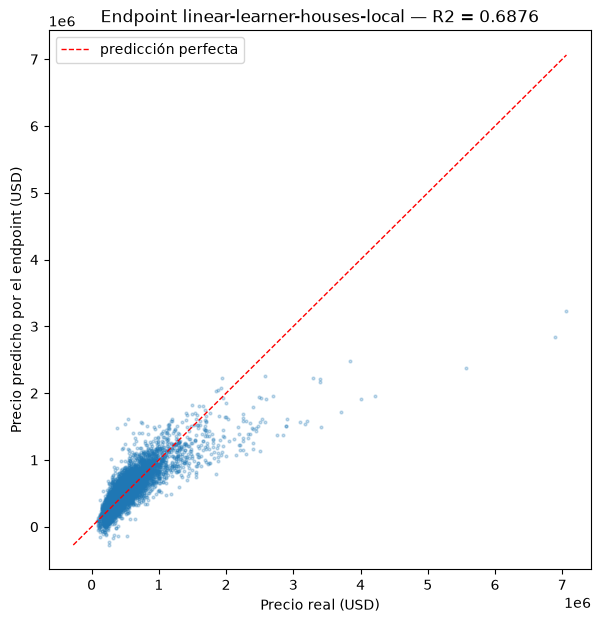

In [40]:
# Gráfico: precio real vs precio predicho por el endpoint
plt.figure(figsize=(7, 7))
plt.scatter(y_test, predicciones_endpoint, s=4, alpha=0.25)
limite = [min(y_test.min(), predicciones_endpoint.min()),
          max(y_test.max(), predicciones_endpoint.max())]
plt.plot(limite, limite, 'r--', linewidth=1, label='predicción perfecta')
plt.xlabel('Precio real (USD)')
plt.ylabel('Precio predicho por el endpoint (USD)')
plt.title(f"Endpoint {nombre_endpoint} — R2 = {m_local['R2']:.4f}")
plt.legend()
plt.show()

### Invocación cruda con `boto3`

Así es como lo consume una aplicación de verdad — sin el SDK de SageMaker, solo `boto3`. Es
literalmente el código de `AWS-Consumo-del-Modelo-ML-Regresion/consumo-simple-de-modelo-linear-learned.py`,
y funciona sin cambiarle una línea.

In [41]:
runtime = boto3.client('sagemaker-runtime')

payload = ','.join(map(str, casa))          # "3,1.0,1180,5650,..."

respuesta = runtime.invoke_endpoint(
    EndpointName=nombre_endpoint,
    ContentType='text/csv',
    Body=payload.encode('utf-8'),
)

cuerpo = json.loads(respuesta['Body'].read().decode('utf-8'))
print('JSON devuelto:', cuerpo)
print(f"Predicción: ${cuerpo['predictions'][0]['score']:,.2f}")

JSON devuelto: {'predictions': [{'score': 224453.12529499497}]}
Predicción: $224,453.13


### Dejar el nombre del endpoint en el `.env` de las apps de consumo

In [42]:
ruta_env = pathlib.Path('AWS-Consumo-del-Modelo-ML-Regresion/.env')

if ruta_env.exists():
    lineas = ruta_env.read_text(encoding='utf-8').splitlines()
    lineas = [f'SAGEMAKER_ENDPOINT_NAME={nombre_endpoint}'
              if l.startswith('SAGEMAKER_ENDPOINT_NAME=') else l
              for l in lineas]
    if not any(l.startswith('SAGEMAKER_ENDPOINT_NAME=') for l in lineas):
        lineas.append(f'SAGEMAKER_ENDPOINT_NAME={nombre_endpoint}')
    ruta_env.write_text('\n'.join(lineas) + '\n', encoding='utf-8')
    print(f'{ruta_env} actualizado -> SAGEMAKER_ENDPOINT_NAME={nombre_endpoint}')
else:
    print(f'No existe {ruta_env}. Créalo a partir de env.example con:')
    print(f'   SAGEMAKER_ENDPOINT_NAME={nombre_endpoint}')

AWS-Consumo-del-Modelo-ML-Regresion/.env actualizado -> SAGEMAKER_ENDPOINT_NAME=linear-learner-houses-local


# Apagar el endpoint

Un endpoint se cobra **por hora encendida**, no por predicción. Mientras exista, cuesta.

Descomenta y ejecuta la celda de abajo cuando termines la demostración.

In [43]:
# linear_regressor.delete_endpoint()          # borra el endpoint (deja de cobrar)
# linear_regressor.delete_model()             # borra también el "model" de SageMaker

# Para verificar qué está encendido en la cuenta:
for e in boto3.client('sagemaker').list_endpoints()['Endpoints']:
    print(e['EndpointName'], '|', e['EndpointStatus'], '|', e['CreationTime'])

linear-learner-houses-aws | Creating | 2026-08-20 20:13:38.014000-03:00
linear-learner-houses-local | InService | 2026-08-20 20:10:05.393000-03:00
